# M08 — CTA Historical Test Evaluation

M07 ke 2024 validation par selected **Decision Tree (depth 8)** ko alag bus aur rail datasets par evaluate karte hain. Same training data, features, thresholds aur preprocessing rakhi gayi hain. Tree ka comparison majority aur 91-day historical baselines se hoga.

**Limitations:** 90-day publication delay assumption hai, verified CTA delay nahi. M05 mein 2025 data visualize aur M06 mein class counts dekhe gaye thay; isliye 2025 perfectly untouched test nahi. Historical revisions ke point-in-time snapshots bhi verify nahi huay.


## 1. Libraries aur M06 files

Pehle M06 successfully run honi chahiye; M07 wali scikit-learn dependency use hoti hai. Is notebook ke outputs screen par hain, model file save nahi hoti.


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

if Path("backend/data/processed").is_dir():
    data_folder = Path("backend/data/processed")
elif Path("data/processed").is_dir():
    data_folder = Path("data/processed")
else:
    data_folder = Path("../data/processed")
print("Data folder:", data_folder.resolve())


Data folder: C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\transit-ridership\backend\data\processed


## 2. Data, thresholds aur chronological splits

M06 ke **training-only thresholds** load hote hain. `relative_lag_91` M07 ki tarah 91 din purani rides se banta hai. Target date ki actual rides input nahi hotin. Test ki har date par available 91-day history use hoti hai; ye poora 2025 ek hi date par forecast karna nahi.


In [8]:
features = ["entity_id", "weekday", "month", "day_of_month", "is_weekend", "lag_91_rides", "relative_lag_91"]
classes = ["Low", "Normal", "High"]
data = {}

for name in ["bus", "rail"]:
    df = pd.read_csv(data_folder / f"{name}_model_data.csv", dtype={"entity_id": str}, parse_dates=["date"])
    limits = pd.read_csv(data_folder / f"{name}_train_thresholds.csv", dtype={"entity_id": str})
    df = df.merge(limits[["entity_id", "lower", "upper"]], on="entity_id", how="left", validate="many_to_one")
    if df[["lower", "upper"]].isna().any().any() or (df["upper"] <= df["lower"]).any():
        raise ValueError(f"{name}: training thresholds missing/invalid hain; M06 check karo.")
    df["relative_lag_91"] = (df["lag_91_rides"] - df["lower"]) / (df["upper"] - df["lower"])
    train = df.loc[df["split"] == "train"].copy()
    validation = df.loc[df["split"] == "validation"].copy()
    test = df.loc[df["split"] == "test"].copy()
    if train.empty or validation.empty or test.empty:
        raise ValueError(f"{name}: ek ya zyada splits empty hain; M06 check karo.")
    if (train["date"].min() < pd.Timestamp("2022-01-01") or train["date"].max() > pd.Timestamp("2023-09-30")
        or not validation["date"].between("2024-01-01", "2024-12-31").all()
        or not test["date"].between("2025-01-01", "2025-12-31").all()):
        raise ValueError(f"{name}: dates expected splits se match nahi kartin.")
    data[name] = {"train": train, "validation": validation, "test": test}
    print(f"{name}: train = {len(train):,} | validation = {len(validation):,} | test = {len(test):,}")


bus: train = 61,832 | validation = 41,294 | test = 41,174
rail: train = 77,127 | validation = 51,606 | test = 51,465


## 3. Freeze M07 configuration aur train

Tree parameters `max_depth=8`, `min_samples_leaf=50`, `random_state=42` M07 se fixed hain. Encoder, scaler aur models **sirf training rows par fit** hote hain. Validation/test rows fit mein include nahi hotin. 2024 par score dobara dekhna sirf M07 reproducibility check hai; us par dobara selection nahi karni.


In [9]:
models = {}
majority_models = {}
numerical = ["weekday", "month", "day_of_month", "is_weekend", "lag_91_rides", "relative_lag_91"]

for name, parts in data.items():
    train, validation = parts["train"], parts["validation"]
    preprocessing = ColumnTransformer([
        ("entity", OneHotEncoder(handle_unknown="ignore"), ["entity_id"]),
        ("numeric", StandardScaler(), numerical),
    ])
    model = Pipeline([
        ("prepare", preprocessing),
        ("model", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42)),
    ])
    model.fit(train[features], train["target"])
    models[name] = model
    majority = DummyClassifier(strategy="most_frequent")
    majority.fit(train[features], train["target"])
    majority_models[name] = majority
    check = model.predict(validation[features])
    score = f1_score(validation["target"], check, labels=classes, average="macro", zero_division=0)
    print(f"{name}: 2024 validation macro F1 = {score:.3f} (M07 comparison ke liye)")


bus: 2024 validation macro F1 = 0.625 (M07 comparison ke liye)
rail: 2024 validation macro F1 = 0.643 (M07 comparison ke liye)


## 4. 2025 test comparison

- **Majority:** training mein sabse common class.
- **91-day baseline:** purani rides ko frozen training thresholds se classify karta hai.
- **Decision Tree:** M07 ka frozen selection.

Accuracy ke saath balanced accuracy aur macro F1 dekho. Test results dekhne ke baad isi 2025 set par model tune karke score ko unbiased final test na kaho.


In [10]:
predictions = {}
comparisons = {}
for name, parts in data.items():
    test = parts["test"]
    predictions[name] = {
        "Majority baseline": majority_models[name].predict(test[features]),
        "91-day baseline": np.select(
            [test["lag_91_rides"] <= test["lower"], test["lag_91_rides"] <= test["upper"]],
            ["Low", "Normal"], default="High"),
        "Decision Tree (depth 8)": models[name].predict(test[features]),
    }
    rows = []
    for label, predicted in predictions[name].items():
        rows.append({"Method": label,
                     "Accuracy": accuracy_score(test["target"], predicted),
                     "Balanced accuracy": balanced_accuracy_score(test["target"], predicted),
                     "Macro F1": f1_score(test["target"], predicted, labels=classes, average="macro", zero_division=0)})
    comparisons[name] = pd.DataFrame(rows).set_index("Method")
    print(f"\n{name.upper()} — 2025 test")
    display(comparisons[name].round(3))



BUS — 2025 test


,Accuracy,Balanced accuracy,Macro F1
Method,,,
Majority baseline,0.682,0.333,0.270
91-day baseline,0.721,0.596,0.594
Decision Tree (depth 8),0.690,0.624,0.594



RAIL — 2025 test


,Accuracy,Balanced accuracy,Macro F1
Method,,,
Majority baseline,0.623,0.333,0.256
91-day baseline,0.683,0.586,0.584
Decision Tree (depth 8),0.681,0.639,0.607


## 5. Class-wise performance

Dono tree aur historical baseline ki reports compare karo, especially `Normal` class ka recall aur F1. Matrix mein rows actual aur columns predictions hain.



BUS — 91-day baseline
              precision    recall  f1-score   support

         Low       0.59      0.61      0.60      6536
      Normal       0.34      0.34      0.34      6554
        High       0.84      0.83      0.84     28084

    accuracy                           0.72     41174
   macro avg       0.59      0.60      0.59     41174
weighted avg       0.72      0.72      0.72     41174


BUS — Decision Tree (depth 8)
              precision    recall  f1-score   support

         Low       0.58      0.76      0.66      6536
      Normal       0.27      0.36      0.31      6554
        High       0.88      0.75      0.81     28084

    accuracy                           0.69     41174
   macro avg       0.58      0.62      0.59     41174
weighted avg       0.74      0.69      0.71     41174



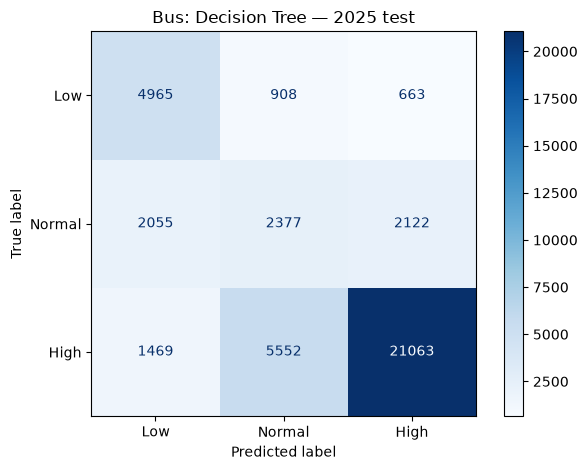


RAIL — 91-day baseline
              precision    recall  f1-score   support

         Low       0.60      0.62      0.61     10490
      Normal       0.33      0.34      0.34      8899
        High       0.81      0.80      0.81     32076

    accuracy                           0.68     51465
   macro avg       0.58      0.59      0.58     51465
weighted avg       0.69      0.68      0.69     51465


RAIL — Decision Tree (depth 8)
              precision    recall  f1-score   support

         Low       0.59      0.82      0.69     10490
      Normal       0.30      0.37      0.33      8899
        High       0.90      0.72      0.80     32076

    accuracy                           0.68     51465
   macro avg       0.60      0.64      0.61     51465
weighted avg       0.73      0.68      0.70     51465



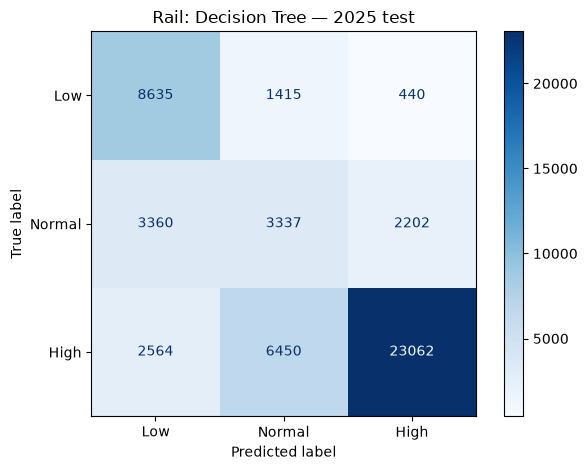

In [11]:
for name, parts in data.items():
    y_test = parts["test"]["target"]
    for method in ["91-day baseline", "Decision Tree (depth 8)"]:
        print(f"\n{name.upper()} — {method}")
        print(classification_report(y_test, predictions[name][method], labels=classes, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name]["Decision Tree (depth 8)"], labels=classes, cmap="Blues", values_format="d")
    plt.title(f"{name.title()}: Decision Tree — 2025 test")
    plt.tight_layout()
    plt.show()


## 6. Test coverage aur interpretation

M06 mein missing 91-day history ya unavailable thresholds wali rows exclude hui thin. Neeche cleaned 2025 rows se test rows compare hain. Ye comparison tab meaningful hai jab cleaned aur M06 files **same data snapshot** se bani hon.


In [12]:
for name, parts in data.items():
    cleaned_path = data_folder / f"{name}_cleaned.csv"
    if cleaned_path.exists():
        dates = pd.read_csv(cleaned_path, usecols=["date"], parse_dates=["date"])["date"]
        candidates = int(dates.between("2025-01-01", "2025-12-31").sum())
        tested = len(parts["test"])
        if candidates:
            print(f"{name}: tested {tested:,} of {candidates:,} cleaned 2025 rows ({tested / candidates:.1%}); same-snapshot assumption")
    else:
        print(f"{name}: cleaned file unavailable; coverage calculate nahi hui.")


bus: tested 41,174 of 42,201 cleaned 2025 rows (97.6%); same-snapshot assumption
rail: tested 51,465 of 52,560 cleaned 2025 rows (97.9%); same-snapshot assumption


## Viva aur limitations

- Tree ki performance ko 91-day rule ke against report karo—agar baseline better hai to woh result bhi honest hai.
- Model 2022–Sep 2023 data se fit hai; 2024 validation aur 2025 test us fit mein include nahi hain.
- 2025 ke har forecast ke liye 91 din purani observed rides available assume hoti hain; delay/revisions verify nahi hue.
- New entities aur missing history excluded hain. `High` relative ridership hai, crowding ya actual bus allocation nahi.
- 2025 pehle EDA mein dekha gaya tha. Is experiment se live performance ya perfectly untouched test ka claim na karo.
